# Binary - Class Weight (imbalanced classes) - Hyperparameter Tuning

In [10]:
import pandas as pd
from sklearn.datasets import make_classification  # synthetic data (fake data)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

In [11]:
# n_informative = 3, # this informative means -> out of 10 features only the 3 features are actually usefull for predicting the target classes.
#                        # the other 7 are just noise or redundant data added to make the dataset look more realistic 
#                        # and challenging for the machine learning model to solve.

In [12]:
# Logistic Regression for imbalanced classes/datasets : binary class weight :

In [1]:
# generate and plot :

from collections import Counter # just to count the inner data points from the features

In [14]:
x, y = make_classification(
    n_samples = 10000, 
    n_features = 2,
    n_clusters_per_class = 1,  # group the data points (classes '0' and '1') into one group or cluster rather that scattering.
    n_redundant = 0, # make sure there is no unwanted and noise features
    weights = [0.90], # to create the highly imbalanced dataset -> 90% for class (0) and 10% for class (1).
    random_state = 10
)

In [15]:
print(Counter(y))

Counter({np.int64(0): 8959, np.int64(1): 1041})


<Axes: xlabel='0', ylabel='1'>

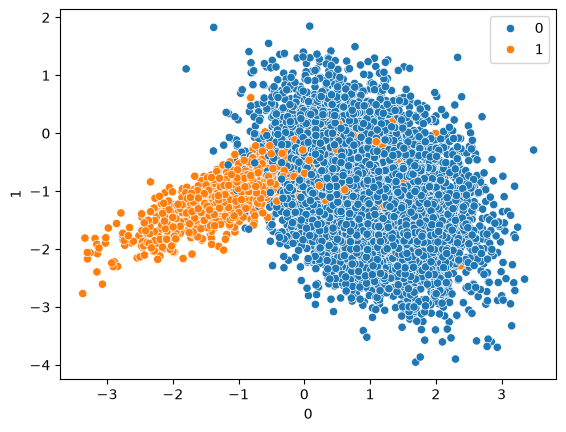

In [16]:
# scatter plot
# to visualize the classes inside the dependent variable - y
sns.scatterplot(
    x = pd.DataFrame(x)[0],
    y = pd.DataFrame(x)[1],
    hue = y
)

In [17]:
# data spliting :

x_train, x_test, y_train, y_test = train_test_split(
    x,y,
    test_size = 0.25,
    random_state = 42
)

In [18]:
# model selection :

model = LogisticRegression()

In [19]:
# setup the arguments values :

penalty = ['l1','l2','elasticnet']
c_values = [0.1, 0.01, 100, 10, 1]
solver = ["newton-cg", 'sag', 'saga','lbfgs', 'liblinear']

In [20]:
# list of punishment settings :

class_weights = [
    {0:w, 1:y} for w in [1,10,50,100]  for y in [1,10,50,100]
    ]

In [21]:
# the combinations for model training :

print(f"Total Model Fits : ", 3*5*5*16)

Total Model Fits :  1200


In [22]:
len(class_weights)

16

In [23]:
class_weights

[{0: 1, 1: 1},
 {0: 1, 1: 10},
 {0: 1, 1: 50},
 {0: 1, 1: 100},
 {0: 10, 1: 1},
 {0: 10, 1: 10},
 {0: 10, 1: 50},
 {0: 10, 1: 100},
 {0: 50, 1: 1},
 {0: 50, 1: 10},
 {0: 50, 1: 50},
 {0: 50, 1: 100},
 {0: 100, 1: 1},
 {0: 100, 1: 10},
 {0: 100, 1: 50},
 {0: 100, 1: 100}]

In [24]:
# objective : make the model more careful
# why ?  to make model predict '1' more easily

# if model make a mistake on class 1 , then more punishment / penalty


# the punishment rule for setting to the model :

# {0: 1, 1: 10} - meaning : class '0'/weight '1' and class '1'/weight '10'
# if model makes mistake on class '1' its 10 times more worse than class '0'

In [25]:
# example :

# Class Weight internal algorithm :

# The Calculation of Loss :
# Loss = loss1 + loss2+ loss3 +....

# predictions : 
# act - 0, pred - 0
# act - 1, pred - 0 (heavy penalty)
# act - 0, pred - 1 (normal penalty)

# each data point's loss is multiplied by its class weight
# {0: 1, 1: 10} 

# The Math :
# class 0 - loss : 1 x log_loss -> manageable
# class 1 - loss : 10 x log_loss -> danger


# loss1 = 0
# loss2 = 10
# loss3 = 1

# total_loss = 11



# balanced 

# for all loss it must calculate with the same penalty like 1

# act - 0, pred - 0
# act - 1, pred - 0 (same penalty)
# act - 0, pred - 1 (same penalty)

# The Math :
# class 0 - loss : 1 x log_loss -> same penalty
# class 1 - loss : 1 x log_loss -> same penalty

In [26]:
# precision recall tradeoff 

# here , by scenario : as per confusion matrix predicting 1 as 0 is under the False Negative - costly/high.

# so, to handle this scenario : I try to reduce the False Negative (recall) (act-1, pred-0)

# effect 1 : recall increases - model catches more actual class '1' - more priority
# effect 2 : precision decreases - class '0' can be predicted as 1 - FP increases

# EOD :
# effect 1 : if recall "increase" (False Negative)(act-1, pred-0) --> precision "decrease" (False Positive)(act-0, pred-1)
# effect 2 : if recall "decrease" (False Negative)(act-1, pred-0) --> precision "increase" (False Positive)(act-0, pred-1)


In [27]:
# parameter settings :

params = dict(
    penalty = penalty,
    C = c_values,
    solver = solver,
    class_weight = class_weights
)

In [28]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [29]:
cv = StratifiedKFold()

In [30]:
# engine settings :

grid = GridSearchCV(
    estimator = model,
    param_grid = params,
    scoring = 'accuracy',# "scoring = precision_macro" is FP is priority /  "scoring = recall_macro"is FN is our priority / for balanced mathematicall score is "scoring = f1"
    cv = cv
)

In [48]:
grid.fit(x_train, y_train)

C:\Users\Vignesh R\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Vignesh R\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warning

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 0.01, ...], 'class_weight': [{0: 1, 1: 1}, {0: 1, 1: 10}, ...], 'penalty': ['l1', 'l2', ...], 'solver': ['newton-cg', 'sag', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo...shuffle=False)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0

In [47]:
# the combinations for model training :
print(f"Total Model Fits : ", 3*5*5*16)

Total Model Fits :  1200


In [49]:
grid.best_params_

{'C': 0.1, 'class_weight': {0: 50, 1: 50}, 'penalty': 'l2', 'solver': 'sag'}

In [50]:
y_pred = grid.predict(x_test)

In [52]:
y_pred

array([1, 0, 0, ..., 0, 0, 1], shape=(2500,))

In [53]:
score = accuracy_score(y_pred, y_test)
print(score)
print(classification_report(y_pred, y_test))
print(confusion_matrix(y_pred, y_test))

0.9508
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      2289
           1       0.66      0.87      0.75       211

    accuracy                           0.95      2500
   macro avg       0.82      0.91      0.86      2500
weighted avg       0.96      0.95      0.95      2500

[[2194   95]
 [  28  183]]
